This notebook is used to demonstrate the utility of autodiff to compute parameter sensitivity useful for tipping point analysis

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
os.environ['JAX_PLATFORM_NAME'] = 'cpu'  # Avoid Metal issues on Apple Silicon

### May Harvesting Model

Harvesting rate $h(t)$ is the bifurcation parameter. We simulate $x(t)$ (biomass) while $h(t)$ ramps from $h_{min}$ to $h_{max}$ and plot $x$ against $h$ until tipping.

Differential equation:

$$
\frac{dx}{dt} = r x \left(1 - \frac{x}{k}\right) - h(t)\,\frac{x^2}{s^2 + x^2} + \sigma\,\xi(t)
$$

- $x$: biomass
- $r$: intrinsic growth rate
- $k$: carrying capacity
- $s$: half-saturation scale for harvesting
- $h(t)$: harvesting rate (bifurcation parameter)
- $\sigma\,\xi(t)$: additive noise

We can compute gradients of model outputs with respect to model parameters using JAX's automatic differentiation.

In [3]:
import jax
import jax.numpy as jnp
from tipbox.bifurcation.may_harvesting import MayHarvestingConfig, MayHarvestingModel

# Key step - create a function that makes a model given parameters
# Default parameters
cfg = MayHarvestingConfig.default()

def run_may_harvesting(cfg):
    model = MayHarvestingModel(cfg)

    _, traj, _, _ = model.simulate(
        key=jax.random.PRNGKey(1),
        total_len=400,
        sigma_tilde=0.01,
        null_simulation=False,
        initial_state=jnp.array(0.8),
    )
    return traj


In [4]:
# VJP is the vector-Jacobian product and calculates the gradient of outputs with respect to inputs
grad = jax.jacrev(run_may_harvesting, allow_int=True)(cfg)

# Compute trajectory and transition index for plotting
traj = run_may_harvesting(cfg)
trans_idx = MayHarvestingModel(cfg).locate_transition(traj, null_simulation=False)


W0000 00:00:1768437486.130117 42956274 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1768437486.174114 42956274 service.cc:145] XLA service 0x1084a8c70 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1768437486.174255 42956274 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1768437486.178893 42956274 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1768437486.178903 42956274 mps_client.cc:384] XLA backend will use up to 5726240768 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M1

systemMemory: 8.00 GB
maxCacheSize: 2.67 GB



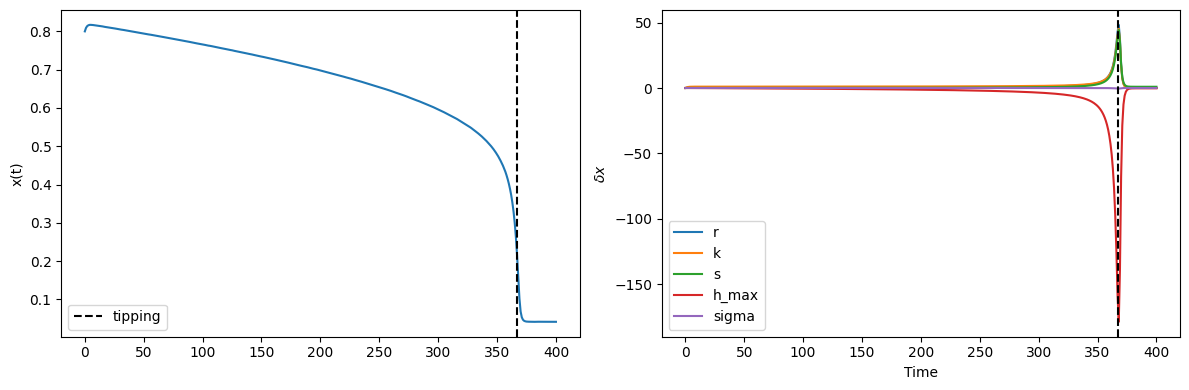

In [5]:
# Plot results
import matplotlib.pyplot as plt
from dataclasses import asdict

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True, figsize=(12, 4))

# Subplot 1: tipping trajectory
ax1.plot(traj[:, 0])
ax1.axvline(trans_idx, color="k", linestyle="--", label="tipping")
ax1.set_ylabel("x(t)")
ax1.legend()

# Subplot 2: sensitivities of dx/dt to selected parameters
for key in ("r", "k", "s", "h_max", "sigma"):
    series = jnp.asarray(asdict(grad)[key][..., 0])
    ax2.plot(series, label=key)

ax2.axvline(trans_idx, color="k", linestyle="--")
ax2.set_xlabel("Time")
ax2.set_ylabel(r"$\delta x$")
ax2.legend()

plt.tight_layout()
plt.show()
